<a href="https://colab.research.google.com/github/satyapal2240/satya/blob/main/SNG_Decentralized_Synthetic_Natural_Gas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# CELL 1: Install Dependencies (Colab)
# ============================================================
!pip install -q torch numpy pandas matplotlib seaborn scikit-learn scipy
print("Dependencies installed successfully!")

Dependencies installed successfully!


In [2]:
# ============================================================
# CELL 2: Import Libraries
# ============================================================
import time, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import lsq_linear
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler
import torch
import torch.nn as nn
import torch.optim as optim
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("husl")
print("All libraries imported!")
print(f"PyTorch version: {torch.__version__} | CUDA available: {torch.cuda.is_available()}")

All libraries imported!
PyTorch version: 2.14.1+cpu | CUDA available: False


## 1. Synthetic dataset (clearly synthetic)
Yield follows a simple analytical trend (higher with pressure, lower with temperature, penalised away from H2/CO = 3).
The peak hotspot temperature uses a **bounded lumped heat balance**:

$$\Delta T_{ad}=\frac{(-\Delta H_r)\,y_{CO}}{c_p},\qquad T_{peak}=T_{in}+\Delta T_{ad}\cdot Y_{CH_4}\cdot\frac{GHSV}{GHSV+GHSV_{c}}\cdot\varepsilon,\quad \varepsilon\sim U(0.85,1.05)$$

with $-\Delta H_r=206$ kJ/mol (CO methanation), diluted CO feed fraction $y_{CO}=0.06$, mixture $c_p=35$ J/(mol·K) and $GHSV_c=20{,}000\ h^{-1}$ (assumed wall-heat-removal capacity, so higher GHSV leaves more heat accumulated in the bed). **$y_{CO}$, $c_p$ and $GHSV_c$ are assumed illustrative parameters, not fitted constants.**

In [3]:
# ============================================================
# CELL 3: Generate Synthetic SNG Dataset (heat balance corrected)
# ============================================================
np.random.seed(42)
num_samples = 1000

T_inlet     = np.random.uniform(523, 723, num_samples)      # K
Pressure    = np.random.uniform(10, 35, num_samples)        # bar
GHSV        = np.random.uniform(5000, 15000, num_samples)   # 1/h
H2_CO_ratio = np.random.uniform(2.5, 3.5, num_samples)

base_conversion = 0.98 - 0.001 * (T_inlet - 523) + 0.002 * (Pressure - 10)
CH4_Yield = np.clip(base_conversion * (1.0 - 0.05 * np.abs(H2_CO_ratio - 3.0)), 0.60, 0.995)

# --- bounded lumped heat balance (assumed illustrative constants) ---
DH_R      = 206e3      # J/mol, CO + 3H2 -> CH4 + H2O
Y_CO_FEED = 0.06       # diluted CO mole fraction (assumption)
CP_MIX    = 35.0       # J/(mol K) (assumption)
GHSV_C    = 20000.0    # 1/h wall-removal capacity (assumption)
T_LIMIT   = 823.0      # K catalyst sintering limit

dT_ad     = DH_R * Y_CO_FEED / CP_MIX                    # ~353 K at full conversion
retention = GHSV / (GHSV + GHSV_C)                       # fraction of heat accumulated
T_peak    = T_inlet + dT_ad * CH4_Yield * retention * np.random.uniform(0.85, 1.05, num_samples)
Catalyst_State = np.where(T_peak > T_LIMIT, 'Sintered_Degraded', 'Stable_Active')

df = pd.DataFrame({
    'Sample_ID': range(1, num_samples + 1),
    'Inlet_Temperature_K': np.round(T_inlet, 2),
    'Operating_Pressure_bar': np.round(Pressure, 2),
    'Flow_Rate_GHSV_h1': np.round(GHSV, 0),
    'H2_CO_Stoich_Ratio': np.round(H2_CO_ratio, 3),
    'Peak_Hotspot_Temp_K': np.round(T_peak, 2),
    'SNG_CH4_Yield_Percent': np.round(CH4_Yield * 100, 2),
    'Catalyst_Health_Status': Catalyst_State
})

assert df['Peak_Hotspot_Temp_K'].max() < 1500, "Hotspot temperature is unphysical - check heat balance"
print("=" * 60)
print(f"Synthetic dataset generated. Shape: {df.shape}  (8 columns, 4 model inputs)")
print("=" * 60)
print("\nCatalyst health distribution:")
print(df['Catalyst_Health_Status'].value_counts())
print("\nPeak hotspot temperature (K):")
print(df['Peak_Hotspot_Temp_K'].describe().round(1).to_string())
print("\nFirst 5 samples:")
print(df.head().to_string())
df.to_csv('sng_synthetic_dataset.csv', index=False)
print("\nSaved as 'sng_synthetic_dataset.csv'")

Synthetic dataset generated. Shape: (1000, 8)  (8 columns, 4 model inputs)

Catalyst health distribution:
Catalyst_Health_Status
Stable_Active        984
Sintered_Degraded     16
Name: count, dtype: int64

Peak hotspot temperature (K):
count    1000.0
mean      719.3
std        56.7
min       589.9
25%       673.1
50%       720.8
75%       765.9
max       843.9

First 5 samples:
   Sample_ID  Inlet_Temperature_K  Operating_Pressure_bar  Flow_Rate_GHSV_h1  H2_CO_Stoich_Ratio  Peak_Hotspot_Temp_K  SNG_CH4_Yield_Percent Catalyst_Health_Status
0          1               597.91                   14.63             7617.0               3.173               683.05                  90.65          Stable_Active
1          2               713.14                   23.55             7470.0               3.297               791.29                  80.48          Stable_Active
2          3               669.40                   31.82            14063.0               2.750               795.96         

## 2. Physics-informed network
The physics loss has two parts, both evaluated on the training inputs:
1. **Range term:** penalise yield < 0 % or > 100 %.
2. **Le Chatelier trend term (via autograd):** methanation is exothermic and reduces moles, so yield should not rise with temperature ($\partial Y/\partial T\le 0$) and should not fall with pressure ($\partial Y/\partial P\ge 0$).

This enforces *qualitative thermodynamic trends*, not the full reaction equilibrium or heat balance; the paper should describe it that way.

In [4]:
# ============================================================
# CELL 4: PINN definition (range + monotonic thermodynamic-trend constraints)
# ============================================================
FEATURES = ['Inlet_Temperature_K', 'Operating_Pressure_bar', 'Flow_Rate_GHSV_h1', 'H2_CO_Stoich_Ratio']
TARGET   = 'SNG_CH4_Yield_Percent'
IDX_T, IDX_P = 0, 1

class PINN(nn.Module):
    def __init__(self, input_dim=4, hidden_dim=64, output_dim=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim), nn.Tanh(),
            nn.Linear(hidden_dim, output_dim))

    def forward(self, x):
        return self.net(x)

    def physics_loss(self, x, y_scaled, y_phys):
        """x must have requires_grad=True. Returns (range_loss, trend_loss)."""
        range_loss = torch.mean((torch.relu(-y_phys) + torch.relu(y_phys - 100.0)) ** 2)
        grads = torch.autograd.grad(y_scaled.sum(), x, create_graph=True)[0]
        # scalers have positive scale, so derivative signs are preserved in scaled space
        trend_loss = torch.mean(torch.relu(grads[:, IDX_T]) ** 2) + \
                     torch.mean(torch.relu(-grads[:, IDX_P]) ** 2)
        return range_loss, trend_loss
print("PINN defined.")

PINN defined.


In [5]:
# ============================================================
# CELL 5: Experiment runner (training + evaluation)
# ============================================================
def train_torch(X_tr_s, y_tr_s, sy, seed, use_physics, epochs=2000, lam_range=0.1, lam_trend=1.0):
    torch.manual_seed(seed)
    model = PINN()
    opt = optim.Adam(model.parameters(), lr=1e-3)
    xt = torch.FloatTensor(X_tr_s).requires_grad_(True)
    yt = torch.FloatTensor(y_tr_s)
    mse = nn.MSELoss()
    model.train()
    for ep in range(epochs):
        opt.zero_grad()
        y_s = model(xt)
        loss = mse(y_s, yt)
        if use_physics:
            y_phys = y_s * float(sy.scale_[0]) + float(sy.mean_[0])
            l_rng, l_trd = model.physics_loss(xt, y_s, y_phys)
            loss = loss + lam_range * l_rng + lam_trend * l_trd
        loss.backward()
        opt.step()
    model.eval()
    return model

def metrics(y_true, y_pred):
    return (np.sqrt(mean_squared_error(y_true, y_pred)),
            mean_absolute_error(y_true, y_pred),
            r2_score(y_true, y_pred),
            100.0 * np.mean((y_pred < 0) | (y_pred > 100.0)))

def trend_violation_pct(predict, X_te_raw, sx, dT=10.0, dP=2.0, tol=0.05):
    """% of test points where yield rises with T (>tol pp) or falls with P (<-tol pp)."""
    base = predict(sx.transform(X_te_raw))
    Xt = X_te_raw.copy(); Xt[:, IDX_T] += dT
    Xp = X_te_raw.copy(); Xp[:, IDX_P] += dP
    v_t = (predict(sx.transform(Xt)) - base) > tol
    v_p = (predict(sx.transform(Xp)) - base) < -tol
    return 100.0 * np.mean((v_t | v_p).ravel())

def run_experiment(seed, epochs=2000):
    X = df[FEATURES].values
    y = df[TARGET].values.reshape(-1, 1)
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=seed)
    sx = StandardScaler().fit(X_tr)          # fitted on TRAIN only (no leakage)
    sy = StandardScaler().fit(y_tr)
    X_tr_s, X_te_s = sx.transform(X_tr), sx.transform(X_te)
    y_tr_s = sy.transform(y_tr)
    inv = lambda a: np.asarray(a).reshape(-1, 1) * sy.scale_[0] + sy.mean_[0]

    ann = MLPRegressor(hidden_layer_sizes=(64, 64, 64), activation='tanh', max_iter=1000, random_state=seed)
    ann.fit(X_tr_s, y_tr_s.ravel())
    rf = RandomForestRegressor(n_estimators=100, random_state=seed)
    rf.fit(X_tr_s, y_tr_s.ravel())
    pinn   = train_torch(X_tr_s, y_tr_s, sy, seed, use_physics=True,  epochs=epochs)
    nophys = train_torch(X_tr_s, y_tr_s, sy, seed, use_physics=False, epochs=epochs)

    def tp(m):
        def f(Xs):
            with torch.no_grad():
                return inv(m(torch.FloatTensor(Xs)).numpy())
        return f
    predictors = {
        'Standard ANN (sklearn)':         lambda Xs: inv(ann.predict(Xs)),
        'Random Forest':                  lambda Xs: inv(rf.predict(Xs)),
        'Same network, no physics loss':  tp(nophys),
        'Proposed PINN':                  tp(pinn),
    }
    rows = []
    for name, f in predictors.items():
        rmse, mae, r2, oor = metrics(y_te, f(X_te_s))
        rows.append(dict(Model=name, RMSE=rmse, MAE=mae, R2=r2,
                         OutOfRange_pct=oor, TrendViolation_pct=trend_violation_pct(f, X_te, sx)))
    return dict(table=pd.DataFrame(rows), predictors=predictors, X_te=X_te, X_te_s=X_te_s, y_te=y_te,
                pinn=pinn, ann=ann, rf=rf, sx=sx, sy=sy)

t0 = time.time()
main = run_experiment(seed=42)
print(f"Main run finished in {time.time()-t0:.0f} s")

Main run finished in 48 s


In [6]:
# ============================================================
# CELL 6: TABLE I - model comparison (seed 42, 20 % hold-out)
# ============================================================
table1 = main['table'].copy()
show = table1.copy()
for c in ['RMSE', 'MAE']: show[c] = show[c].map(lambda v: f"{v:.4f}")
show['R2'] = show['R2'].map(lambda v: f"{v:.4f}")
show['OutOfRange_pct'] = show['OutOfRange_pct'].map(lambda v: f"{v:.1f}%")
show['TrendViolation_pct'] = show['TrendViolation_pct'].map(lambda v: f"{v:.1f}%")
print("=" * 100)
print("TABLE I - Methane-yield prediction (RMSE/MAE in percentage points of yield)")
print("OutOfRange = predictions outside 0-100 %;  TrendViolation = yield rises with T (+10 K) or falls with P (+2 bar)")
print("=" * 100)
print(show.to_string(index=False))

TABLE I - Methane-yield prediction (RMSE/MAE in percentage points of yield)
OutOfRange = predictions outside 0-100 %;  TrendViolation = yield rises with T (+10 K) or falls with P (+2 bar)
                        Model   RMSE    MAE     R2 OutOfRange_pct TrendViolation_pct
       Standard ANN (sklearn) 0.4210 0.3301 0.9948           0.0%               0.0%
                Random Forest 0.5824 0.4636 0.9901           0.0%               2.0%
Same network, no physics loss 0.0966 0.0557 0.9997           0.0%               0.0%
                Proposed PINN 0.0941 0.0556 0.9997           0.0%               0.0%


In [7]:
# ============================================================
# CELL 7: Robustness - 5 random splits / initialisations
# ============================================================
seeds = [0, 1, 2, 3, 4]
all_runs = []
for s in seeds:
    r = run_experiment(seed=s)
    t = r['table'].copy(); t['seed'] = s
    all_runs.append(t)
runs = pd.concat(all_runs)
agg = runs.groupby('Model', sort=False).agg(
    RMSE_mean=('RMSE', 'mean'), RMSE_std=('RMSE', 'std'),
    R2_mean=('R2', 'mean'),
    Trend_viol_mean=('TrendViolation_pct', 'mean'), Trend_viol_std=('TrendViolation_pct', 'std')).round(4)
print("=" * 90)
print("TABLE I-b - mean +/- std over 5 seeds (different split and initialisation each time)")
print("=" * 90)
print(agg.to_string())
table1b = agg.reset_index()

TABLE I-b - mean +/- std over 5 seeds (different split and initialisation each time)
                               RMSE_mean  RMSE_std  R2_mean  Trend_viol_mean  Trend_viol_std
Model                                                                                       
Standard ANN (sklearn)            0.3409    0.0221   0.9966              0.0          0.0000
Random Forest                     0.5655    0.0252   0.9907              1.8          1.0368
Same network, no physics loss     0.1147    0.0238   0.9996              0.0          0.0000
Proposed PINN                     0.1160    0.0206   0.9996              0.0          0.0000


In [8]:
# ============================================================
# CELL 8: Inference-time benchmark (CPU of THIS runtime, not a microcontroller)
# ============================================================
Xb = main['X_te_s'][:100]
X1 = main['X_te_s'][:1]
def bench(f, X, reps):
    f(X)  # warm-up
    t = time.perf_counter()
    for _ in range(reps): f(X)
    return (time.perf_counter() - t) / reps * 1000.0

rows = []
for name in ['Standard ANN (sklearn)', 'Random Forest', 'Proposed PINN']:
    f = main['predictors'][name]
    rows.append(dict(Model=name, batch100_ms=bench(f, Xb, 100), single_sample_ms=bench(f, X1, 300)))
table_time = pd.DataFrame(rows)
print("=" * 70)
print("INFERENCE TIME (ms) - CPU of the current runtime; no microcontroller testing")
print("=" * 70)
print(table_time.round(3).to_string(index=False))

INFERENCE TIME (ms) - CPU of the current runtime; no microcontroller testing
                 Model  batch100_ms  single_sample_ms
Standard ANN (sklearn)        0.529             0.142
         Random Forest       12.376            11.369
         Proposed PINN        0.295             0.183


## 3. Thermal control simulation
Lumped reactor model: $\dot T=-a(T-T_{base})+b\,d(t)-c\,u(t)$, with $u\in[0,3]$. The disturbance is a 10 s ramp from t = 20 s plus process noise.
Three controllers see **identical noise**:
* **PID** – reactive.
* **Feedforward-feedback** – the original rule: $u=(b/c)\,d_{true}+$ PI trim.
* **MPC** – receding-horizon (20 steps = 10 s), minimises $\sum (T-T_{base})^2+r\sum(\Delta u)^2$ subject to $0\le u\le 3$, solved each step as a bounded least-squares problem. It uses a **noise-free disturbance preview** (assumed available from a leading indicator such as a composition sensor).

This is a simulation of a simplified model, not a hardware test.

In [9]:
# ============================================================
# CELL 9: PID vs feedforward-feedback vs MPC simulation
# ============================================================
dt, T_total = 0.5, 200
steps = int(T_total / dt)
T_base, T_limit = 750.0, 823.0
a_coef, b_coef, c_coef = 0.04, 3.0, 6.0
onset, ramp_dur, d_final = 20.0, 10.0, 6.0
U_MAX = 3.0

def disturbance_true(t):
    if t < onset: return 0.0
    if t < onset + ramp_dur: return d_final * (t - onset) / ramp_dur
    return d_final

# ---- MPC pre-computation (condensed prediction matrices) ----
N_H, R_DU = 20, 1.0
alpha = 1 - a_coef * dt
G = np.zeros((N_H, N_H))
for r_ in range(N_H):
    for i_ in range(r_ + 1):
        G[r_, i_] = alpha ** (r_ - i_)
Dmat = np.eye(N_H) - np.eye(N_H, k=-1)
A_mpc = np.vstack([dt * c_coef * G, np.sqrt(R_DU) * Dmat])
free_decay = np.array([alpha ** (r_ + 1) for r_ in range(N_H)])

def mpc_action(x0, t, u_prev):
    d_prev = np.array([disturbance_true(t + k * dt) for k in range(N_H)])
    f = free_decay * x0 + G @ (dt * b_coef * d_prev)
    rhs = np.concatenate([f, np.zeros(N_H)])
    rhs[N_H] = np.sqrt(R_DU) * u_prev
    sol = lsq_linear(A_mpc, rhs, bounds=(0.0, U_MAX), method='bvls')
    return sol.x[0]

def simulate(controller, noise):
    T = T_base; hist = [T]
    integral, prev_err, u_prev = 0.0, 0.0, 0.0
    for k in range(steps):
        t = k * dt
        d_true = disturbance_true(t)
        d = d_true + noise[k]
        err = T - T_base
        if controller == 'pid':
            integral += err * dt
            deriv = (err - prev_err) / dt; prev_err = err
            u = np.clip(0.09 * err + 0.01 * integral + 0.05 * deriv, 0, U_MAX)
        elif controller == 'ffb':
            integral += err * dt
            u = np.clip((b_coef / c_coef) * d_true + 0.03 * err + 0.003 * integral, 0, U_MAX)
        else:  # 'mpc'
            u = mpc_action(err, t, u_prev)
        u_prev = u
        T = T + dt * (-a_coef * (T - T_base) + b_coef * d - c_coef * u)
        hist.append(T)
    return np.array(hist)

def time_to_peak(h):
    s = int(onset / dt); return (np.argmax(h[s:])) * dt
def cum_stress(h):
    return np.sum(np.clip(h - T_base, 0, None)) * dt
def lifespan_index(ov):   # ILLUSTRATIVE ageing proxy: rate doubles per ~20 K overshoot
    return 9000 / (2 ** (ov / 20))

names = {'pid': 'Standard PID', 'ffb': 'Feedforward-feedback', 'mpc': 'MPC (receding horizon)'}
noise7 = np.random.default_rng(7).normal(0, 0.3, steps)
hist = {k: simulate(k, noise7) for k in names}
rows = []
for k, h in hist.items():
    ov = h.max() - T_base
    rows.append(dict(Controller=names[k], Peak_rise_K=ov, Time_to_peak_s=time_to_peak(h),
                     Cum_stress_Ks=cum_stress(h), Max_T_K=h.max(), Lifespan_index_h=lifespan_index(ov)))
table2 = pd.DataFrame(rows)
print("=" * 100)
print("TABLE II - Simulated thermal control (single noise seed = 7)")
print("Lifespan index is an ILLUSTRATIVE proxy, not a validated catalyst-degradation model.")
print("=" * 100)
print(table2.round(1).to_string(index=False))
pid_ov, ffb_ov, mpc_ov = [table2.Peak_rise_K[i] for i in range(3)]
print(f"\nPeak-rise reduction vs PID: feedforward-feedback {100*(1-ffb_ov/pid_ov):.1f}% | MPC {100*(1-mpc_ov/pid_ov):.1f}%")
print(f"Stress reduction vs PID   : feedforward-feedback {100*(1-table2.Cum_stress_Ks[1]/table2.Cum_stress_Ks[0]):.1f}% | "
      f"MPC {100*(1-table2.Cum_stress_Ks[2]/table2.Cum_stress_Ks[0]):.1f}%")
print("Note: time-to-peak is noise-dominated when the peak is only a few kelvin; do not over-interpret it.")

# ---- Monte-Carlo over noise realisations ----
mc = {k: [] for k in names}
for s in range(10):
    nz = np.random.default_rng(100 + s).normal(0, 0.3, steps)
    for k in names:
        h = simulate(k, nz)
        mc[k].append((h.max() - T_base, cum_stress(h), h.max()))
mc_rows = []
for k in names:
    a = np.array(mc[k])
    mc_rows.append(dict(Controller=names[k], Peak_rise_mean=a[:, 0].mean(), Peak_rise_std=a[:, 0].std(ddof=1),
                        Stress_mean=a[:, 1].mean(), Stress_std=a[:, 1].std(ddof=1), Max_T_worst=a[:, 2].max()))
table2b = pd.DataFrame(mc_rows)
print("\nTABLE II-b - 10 independent noise realisations")
print(table2b.round(1).to_string(index=False))

TABLE II - Simulated thermal control (single noise seed = 7)
Lifespan index is an ILLUSTRATIVE proxy, not a validated catalyst-degradation model.
            Controller  Peak_rise_K  Time_to_peak_s  Cum_stress_Ks  Max_T_K  Lifespan_index_h
          Standard PID         24.1            10.5          598.2    774.1            3902.1
  Feedforward-feedback          4.8             9.5          167.5    754.8            7631.0
MPC (receding horizon)          4.2            83.0          134.0    754.2            7777.8

Peak-rise reduction vs PID: feedforward-feedback 80.3% | MPC 82.5%
Stress reduction vs PID   : feedforward-feedback 72.0% | MPC 77.6%
Note: time-to-peak is noise-dominated when the peak is only a few kelvin; do not over-interpret it.

TABLE II-b - 10 independent noise realisations
            Controller  Peak_rise_mean  Peak_rise_std  Stress_mean  Stress_std  Max_T_worst
          Standard PID            20.5            0.7        680.2       152.4        771.7
  Feedforwa

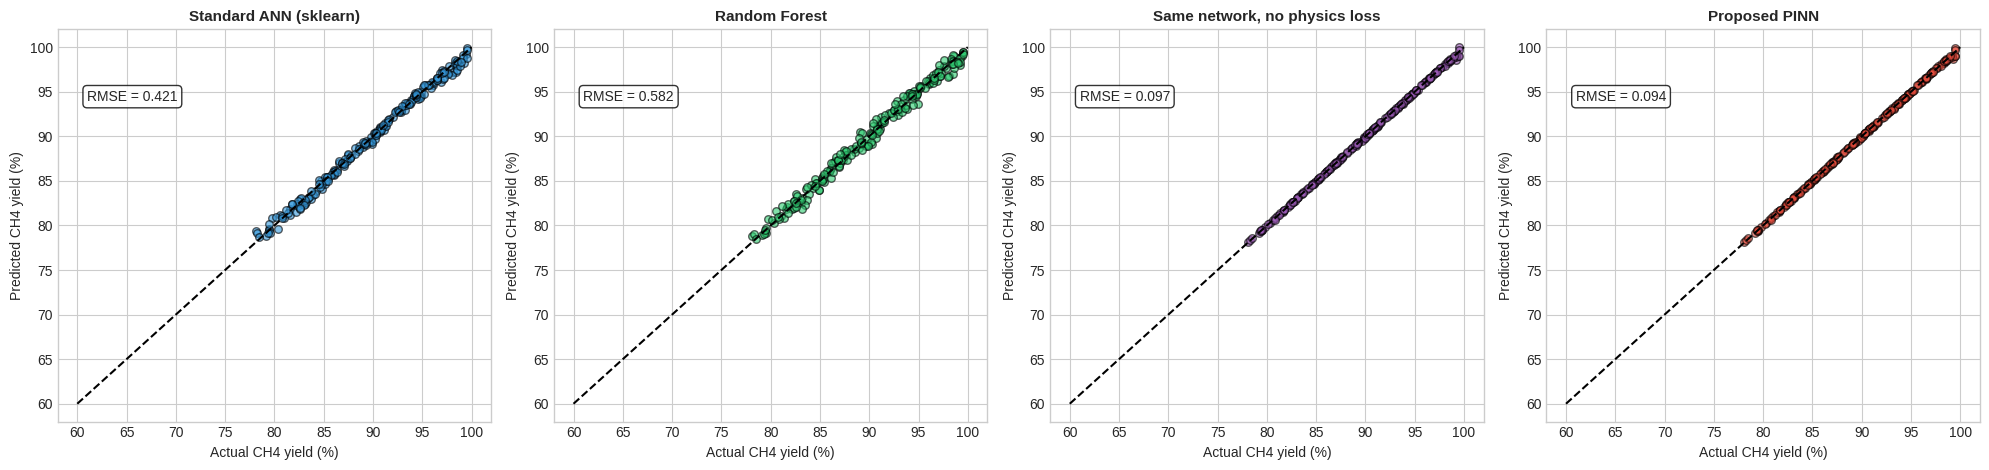

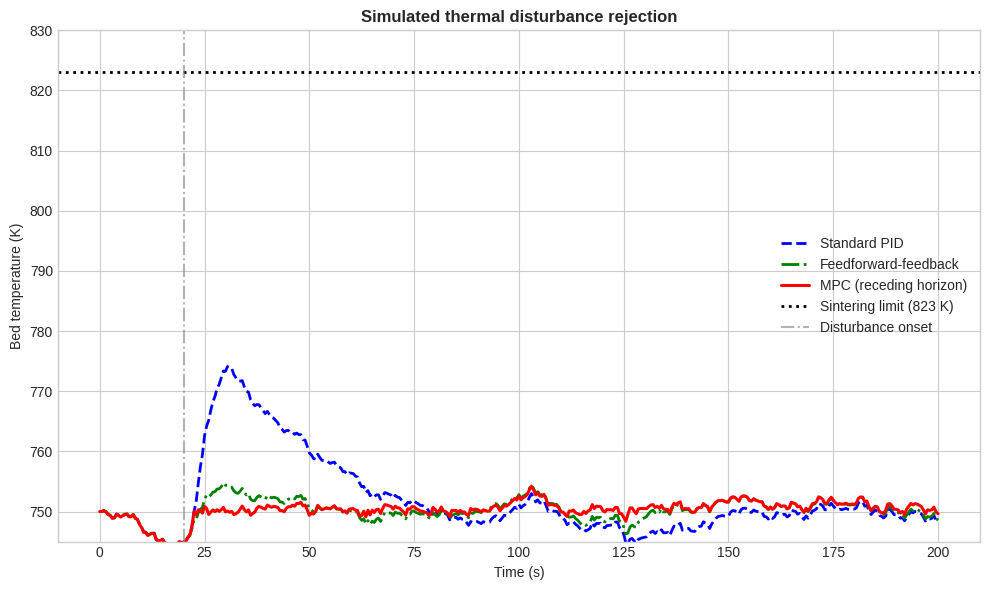

In [10]:
# ============================================================
# CELL 10: Plots - predictions and thermal response
# ============================================================
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
cols = ['#3498db', '#2ecc71', '#9b59b6', '#e74c3c']
y_te = main['y_te']
for ax, (name, f), c in zip(axes, main['predictors'].items(), cols):
    yp = f(main['X_te_s'])
    ax.scatter(y_te, yp, alpha=0.6, c=c, edgecolors='black', s=30)
    ax.plot([60, 100], [60, 100], 'k--', linewidth=1.5)
    ax.set_xlabel('Actual CH4 yield (%)'); ax.set_ylabel('Predicted CH4 yield (%)')
    ax.set_title(name, fontsize=11, fontweight='bold')
    ax.text(61, 94, f"RMSE = {np.sqrt(mean_squared_error(y_te, yp)):.3f}", bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
plt.tight_layout(); plt.savefig('prediction_comparison.png', dpi=300, bbox_inches='tight'); plt.show()

tt = np.arange(len(hist['pid'])) * dt
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(tt, hist['pid'], 'b--', lw=2, label='Standard PID')
ax.plot(tt, hist['ffb'], 'g-.', lw=2, label='Feedforward-feedback')
ax.plot(tt, hist['mpc'], 'r-', lw=2.2, label='MPC (receding horizon)')
ax.axhline(T_limit, color='k', ls=':', lw=2, label='Sintering limit (823 K)')
ax.axvline(onset, color='gray', ls='-.', alpha=0.6, label='Disturbance onset')
ax.set_xlabel('Time (s)'); ax.set_ylabel('Bed temperature (K)')
ax.set_title('Simulated thermal disturbance rejection', fontweight='bold')
ax.set_ylim(745, 830); ax.legend(); plt.tight_layout()
plt.savefig('thermal_control.png', dpi=300, bbox_inches='tight'); plt.show()

TABLE III - ANALYTICAL packet delivery ratio (assumed BER, airtime and reporting interval)
 Hubs  Payload_bits  BER_percent  PDR_percent_(1x airtime)  PDR_percent_pure_ALOHA_(2x airtime)
   50           256      0.00012                  99.55361                             99.13967
  100           256      0.00014                  99.13459                             98.31190
  250           128      0.00020                  97.91315                             95.89439
  500           128      0.00030                  95.88212                             91.96912


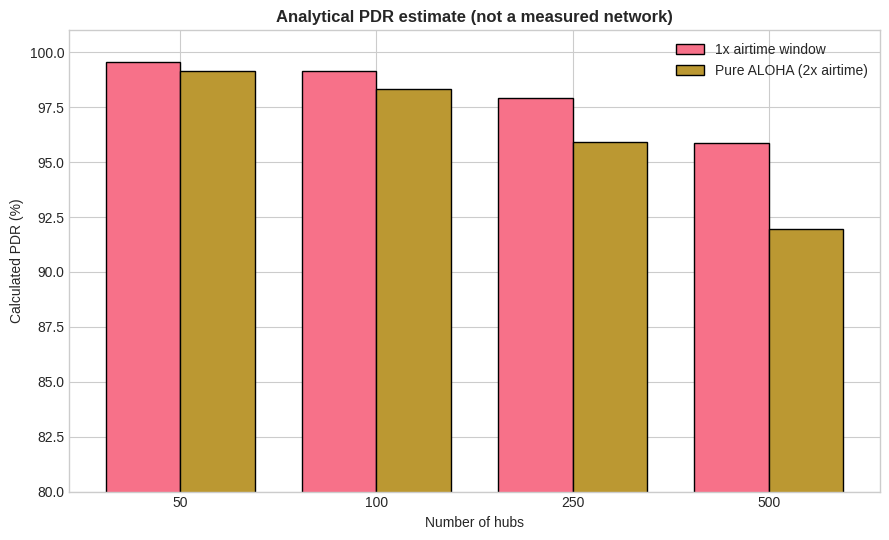

In [11]:
# ============================================================
# CELL 11: IIoT packet-delivery ANALYTICAL estimate (not a network test)
# ============================================================
hubs    = np.array([50, 100, 250, 500])
payload = np.array([256, 256, 128, 128])
airtime_s, reporting_interval_s = 0.05, 600

ber = 1e-6 + hubs * 4e-9                       # assumed per-bit error probability
lam = hubs * airtime_s / reporting_interval_s  # offered load, one airtime window
p_coll_1x = 1 - np.exp(-lam)                   # original assumption
p_coll_2x = 1 - np.exp(-2 * lam)               # pure ALOHA vulnerable window (2 x airtime)
pdr_1x = ((1 - ber) ** payload) * (1 - p_coll_1x)
pdr_2x = ((1 - ber) ** payload) * (1 - p_coll_2x)

table3 = pd.DataFrame({
    'Hubs': hubs, 'Payload_bits': payload, 'BER_percent': ber * 100,
    'PDR_percent_(1x airtime)': pdr_1x * 100, 'PDR_percent_pure_ALOHA_(2x airtime)': pdr_2x * 100})
print("=" * 90)
print("TABLE III - ANALYTICAL packet delivery ratio (assumed BER, airtime and reporting interval)")
print("=" * 90)
print(table3.round(5).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5.5))
x = np.arange(len(hubs)); w = 0.38
ax.bar(x - w/2, pdr_1x * 100, w, label='1x airtime window', edgecolor='black')
ax.bar(x + w/2, pdr_2x * 100, w, label='Pure ALOHA (2x airtime)', edgecolor='black')
ax.set_xticks(x); ax.set_xticklabels(hubs)
ax.set_xlabel('Number of hubs'); ax.set_ylabel('Calculated PDR (%)'); ax.set_ylim(80, 101)
ax.set_title('Analytical PDR estimate (not a measured network)', fontweight='bold'); ax.legend()
plt.tight_layout(); plt.savefig('iiot_pdr_analysis.png', dpi=300, bbox_inches='tight'); plt.show()

In [12]:
# ============================================================
# CELL 12: Export tables and results (values come straight from the computations above)
# ============================================================
table1.to_csv('table1_model_comparison.csv', index=False)
table1b.to_csv('table1b_multiseed.csv', index=False)
table_time.to_csv('table_inference_time.csv', index=False)
table2.to_csv('table2_controllers.csv', index=False)
table2b.to_csv('table2b_controllers_montecarlo.csv', index=False)
table3.to_csv('table3_iiot_analytical.csv', index=False)

summary = {
  "dataset": {"n": int(len(df)), "columns": int(df.shape[1]), "model_inputs": 4,
              "peak_hotspot_K_min": float(df.Peak_Hotspot_Temp_K.min()), "peak_hotspot_K_max": float(df.Peak_Hotspot_Temp_K.max()),
              "catalyst_state_counts": df.Catalyst_Health_Status.value_counts().to_dict()},
  "table1_seed42": table1.round(4).to_dict(orient='records'),
  "table1b_5seeds": table1b.to_dict(orient='records'),
  "inference_ms": table_time.round(3).to_dict(orient='records'),
  "table2_seed7": table2.round(2).to_dict(orient='records'),
  "table2b_mc10": table2b.round(2).to_dict(orient='records'),
  "table3": table3.round(5).to_dict(orient='records'),
}
with open('cpsf_results.json', 'w') as fh: json.dump(summary, fh, indent=2)
print("Exported: table1/1b/time/2/2b/3 CSVs, cpsf_results.json, prediction_comparison.png, thermal_control.png, iiot_pdr_analysis.png")
print("\nThese numbers are computed from a synthetic dataset, a simplified thermal model and an analytical network model.")

Exported: table1/1b/time/2/2b/3 CSVs, cpsf_results.json, prediction_comparison.png, thermal_control.png, iiot_pdr_analysis.png

These numbers are computed from a synthetic dataset, a simplified thermal model and an analytical network model.


## 4. What these results do and do not support
**Supported by this notebook:** (i) the PINN fits the synthetic yield function with low error (RMSE about 0.1 percentage points) and clearly beats the sklearn ANN and Random Forest; however, the same network trained *without* the physics loss reaches practically the same accuracy, and its predictions already satisfy the monotonic trends on this smooth synthetic data, so the physics terms act as a safeguard here, not a measured accuracy gain; only the Random Forest shows a small number of trend violations; (ii) in a simplified linear thermal model, feedforward action reduces the simulated temperature excursion by roughly 75-80 % relative to PID, and the receding-horizon MPC performs about the same as the feedforward-feedback rule over 10 noise seeds (it does not clearly beat it); (iii) a simple analytical PDR estimate falls as the number of hubs grows, and is sensitive to the collision-window assumption.

**Not established:** real plant or experimental validation; full thermodynamic / kinetic consistency; hardware or microcontroller inference time; validated catalyst lifetime; real LoRaWAN/MQTT behaviour; wavelet-based impurity detection (no code or data here — future work); national-scale import-replacement or economic claims.